# Credit Card Fraud Detection — Cost-Sensitive Extension

Notebooks 01–03 are the base project. This notebook extends it with five changes:
1. **Leak-free, time-based evaluation**: train on the past, test on the future.
2. **Real-world metrics**: correct for the subsample (0.94% fraud here vs 0.17% in reality).
3. **Stronger models**: LightGBM vs the base Random Forest and Logistic Regression.
4. **Cost-based decision threshold**: choose the cutoff that minimizes dollars lost, not one that maximizes F1.
5. **Explainability**: why the model flags a transaction.

## 1. Setup & Time-Based Split
The base project shuffled rows randomly before splitting. A real fraud model is trained on **past** transactions and used on **future** ones, so we sort by `Time` and split chronologically:
- **Train** (first 60%): the model learns here.
- **Validation** (next 20%): used later to choose the decision threshold.
- **Test** (last 20%): touched only for final scoring.

We load the **raw** CSV, not the pre-scaled one from notebook 02, because that scaler was fit on all rows, including test rows (a small data leak).

In [4]:
# --- Colab setup ---
from google.colab import drive
drive.mount('/content/drive')
import os
os.chdir('/content/drive/MyDrive/credit-card-fraud-detection')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import average_precision_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
sns.set_style("whitegrid")

# Load RAW data, drop duplicates, sort oldest → newest
df = (pd.read_csv("data/creditcard.csv")
        .drop_duplicates()
        .sort_values("Time")
        .reset_index(drop=True))
FEATURES = [c for c in df.columns if c != "Class"]

# Time-based split: past → train, near future → validation, far future → test
n = len(df)
train = df.iloc[: int(n * 0.6)]
val   = df.iloc[int(n * 0.6): int(n * 0.8)]
test  = df.iloc[int(n * 0.8):]

for name, part in [("Train", train), ("Valid", val), ("Test", test)]:
    print(f"{name}: {len(part):>6,} rows | {part['Class'].sum():>3} fraud "
          f"| fraud rate {part['Class'].mean():.2%} "
          f"| hours {part['Time'].min()/3600:4.1f} → {part['Time'].max()/3600:4.1f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train: 30,263 rows | 342 fraud | fraud rate 1.13% | hours  0.0 → 33.4
Valid: 10,088 rows |  57 fraud | fraud rate 0.57% | hours 33.4 → 40.4
Test: 10,088 rows |  74 fraud | fraud rate 0.73% | hours 40.4 → 48.0


## 2. Evaluation Function with Real-World Correction
Our file keeps all frauds but only 50,000 of the original 284,315 legitimate transactions. So each legit row here **stands in for about 5.69 real legit transactions**. Without correcting for this, false alarms (and therefore precision) look about 5.7× better than they would in production.

`evaluate()` reports raw metrics, **real-world metrics** (legit rows weighted ×5.69), and plain counts: frauds caught, frauds missed, and false alarms.

In [5]:
# Each legit row in our subsample represents ~5.69 real legit transactions
REAL_LEGIT_WEIGHT = 284_315 / 50_000

def evaluate(name, y_true, prob, threshold=0.5):
    """Score a model's fraud probabilities at a given cutoff."""
    y_true = np.asarray(y_true)
    pred = (prob >= threshold).astype(int)                     # probability → yes/no
    weights = np.where(y_true == 1, 1.0, REAL_LEGIT_WEIGHT)    # upweight legit rows
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()

    return {
        "Model": name,
        "PR-AUC": average_precision_score(y_true, prob),
        "PR-AUC (real-world)": average_precision_score(y_true, prob, sample_weight=weights),
        "Recall": tp / (tp + fn),
        "Precision": tp / (tp + fp) if (tp + fp) else 0,
        "Precision (real-world)": tp / (tp + fp * REAL_LEGIT_WEIGHT) if (tp + fp) else 0,
        "Caught": tp, "Missed": fn, "False alarms": fp,
    }

results = []   # every model's scores get collected here for one final comparison table

## 3. How Much Did the Random Split Flatter the Base Model?
We train the same Random Forest as notebook 03 twice:
- **Random split (base method):** shuffled 80/20.
- **Time split (honest method):** train on the first 80% of time, test on the last 20%.

Same model, same amount of training data. The only difference is whether the model is tested on the future.

In [6]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            n_jobs=-1, random_state=42)

# (a) Base method: random 80/20 split
X_tr, X_te, y_tr, y_te = train_test_split(df[FEATURES], df["Class"], test_size=0.2,
                                          random_state=42, stratify=df["Class"])
rf.fit(X_tr, y_tr)
results.append(evaluate("RF — random split (base)", y_te, rf.predict_proba(X_te)[:, 1]))

# (b) Honest method: learn on the past (train + val), test on the future
past = pd.concat([train, val])
rf.fit(past[FEATURES], past["Class"])
results.append(evaluate("RF — time split (honest)", test["Class"],
                        rf.predict_proba(test[FEATURES])[:, 1]))

pd.DataFrame(results).set_index("Model").round(3)

,PR-AUC,PR-AUC (real-world),Recall,Precision,Precision (real-world),Caught,Missed,False alarms
Model,,,,,,,,
RF — random split (base),0.905,0.87,0.811,1.0,1.0,77,18,0
RF — time split (honest),0.874,0.82,0.730,1.0,1.0,54,20,0


## 4. Feature Engineering: Time → Hour of Day
Raw `Time` counts seconds since the dataset began. With a time-based split, every test transaction has a **larger `Time` than anything the model trained on**, so the model has to guess about values it has never seen. That number also isn't meaningful in production ("seconds since some day in 2013").

What does carry over is the **daily rhythm** seen in the EDA: legitimate spending drops at night but fraud doesn't. So we replace `Time` with `Hour` (0–23).

We assume the data starts around midnight; the EDA's low-activity stretch at hours 1–7 supports this.

In [7]:
# Hour of day (0–23): the night-vs-day pattern from the EDA
df["Hour"] = (df["Time"] // 3600) % 24
train = df.iloc[: int(n * 0.6)]                  # re-cut the same split so it includes Hour
val   = df.iloc[int(n * 0.6): int(n * 0.8)]
test  = df.iloc[int(n * 0.8):]

FEATURES_OLD = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount"]
FEATURES     = [f"V{i}" for i in range(1, 29)] + ["Amount", "Hour"]   # Time → Hour

# Is fraud really more common at night?
night = train["Hour"].between(0, 5)
print(f"Fraud rate at night (0–5am): {train.loc[night, 'Class'].mean():.2%}")
print(f"Fraud rate during the day  : {train.loc[~night, 'Class'].mean():.2%}\n")

# A/B test: same Random Forest, raw Time vs Hour, scored on VALIDATION
ab = []
for label, cols in [("RF with raw Time", FEATURES_OLD), ("RF with Hour", FEATURES)]:
    m = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                               n_jobs=-1, random_state=42).fit(train[cols], train["Class"])
    ab.append(evaluate(label, val["Class"], m.predict_proba(val[cols])[:, 1]))
pd.DataFrame(ab).set_index("Model")[["PR-AUC (real-world)", "Caught", "Missed", "False alarms"]].round(3)

Fraud rate at night (0–5am): 2.68%
Fraud rate during the day  : 0.87%



,PR-AUC (real-world),Caught,Missed,False alarms
Model,,,,
RF with raw Time,0.787,37,20,0
RF with Hour,0.780,42,15,1


## 5. Model Comparison on the Honest Split
Three models, all trained on **train only** and compared on **validation**:
- **Logistic Regression**: simple linear baseline. The scaler sits *inside* a pipeline, so it learns from training data only. This fixes the notebook 02 leak.
- **Random Forest**: the base project's winner.
- **LightGBM**: gradient boosting, the industry standard for fraud on tabular data.

We pick the winner by **real-world PR-AUC on validation**. The test set stays untouched until the final step.

Model,Random Forest,LightGBM,Logistic Regression
PR-AUC,0.827,0.830,0.823
PR-AUC (real-world),0.780,0.772,0.746
Recall,0.737,0.754,0.895
Precision,0.977,0.935,0.125
Precision (real-world),0.881,0.716,0.025
Caught,42.000,43.000,51.000
Missed,15.000,14.000,6.000
False alarms,1.000,3.000,357.000


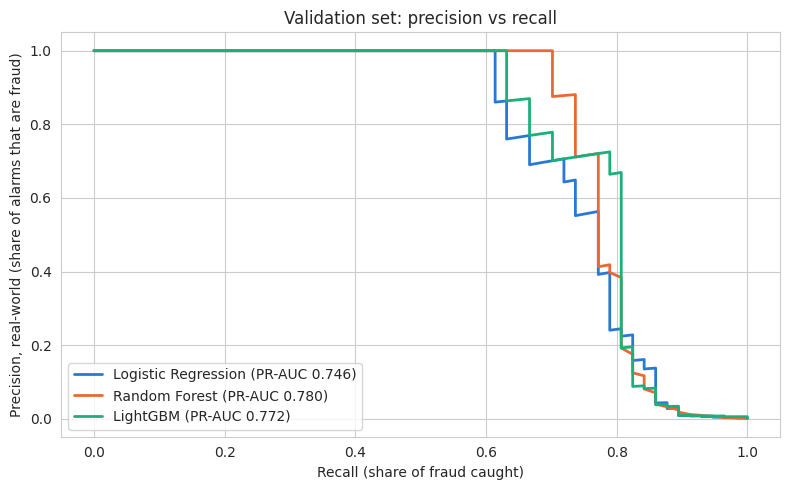

Winner on validation: Random Forest


In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from lightgbm import LGBMClassifier

models = {
    "Logistic Regression": make_pipeline(
        RobustScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(
        n_estimators=500, learning_rate=0.02, min_child_samples=50,
        colsample_bytree=0.5, random_state=42, verbose=-1),
}

val_results, val_probs, test_probs = [], {}, {}
for name, model in models.items():
    model.fit(train[FEATURES], train["Class"])                   # learn on the past only
    val_probs[name]  = model.predict_proba(val[FEATURES])[:, 1]   # for choosing (steps 2–3)
    test_probs[name] = model.predict_proba(test[FEATURES])[:, 1]  # locked away until step 4
    val_results.append(evaluate(name, val["Class"], val_probs[name]))

val_table = (pd.DataFrame(val_results).set_index("Model")
               .sort_values("PR-AUC (real-world)", ascending=False))
display(val_table.round(3).T)

# Precision–recall curves on validation (real-world weighted)
colors = ["#2a78d6", "#eb6834", "#1baf7a"]
weights = np.where(val["Class"] == 1, 1.0, REAL_LEGIT_WEIGHT)
fig, ax = plt.subplots(figsize=(8, 5))
for (name, prob), c in zip(val_probs.items(), colors):
    prec, rec, _ = precision_recall_curve(val["Class"], prob, sample_weight=weights)
    ap = val_table.loc[name, "PR-AUC (real-world)"]
    ax.plot(rec, prec, color=c, linewidth=2, label=f"{name} (PR-AUC {ap:.3f})")
ax.set_xlabel("Recall (share of fraud caught)")
ax.set_ylabel("Precision, real-world (share of alarms that are fraud)")
ax.set_title("Validation set: precision vs recall")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

best_model = val_table.index[0]
print(f"Winner on validation: {best_model}")

## 6. Business Cost: Which Model Loses the Least Money?
Accuracy, F1, and PR-AUC don't say how much money a model saves. We define:
- **Missed fraud** costs its `Amount` (the bank refunds the cardholder).
- **Every alert** costs **€5** of analyst review time (assumption; varied in section 7).
- False alarms are scaled ×5.69 to real-world transaction volume.

**Total cost = € of missed fraud + € of alert reviews.** For each model, we test every cutoff from 0.01 to 0.99 on validation and compare against having **no model at all** (every fraud gets through).

Validation: 57 frauds worth €12,231 → that's the cost with NO model



,Cost @ 0.50 (€),Cheapest cutoff,Cost @ cheapest (€),Saved vs no model
Model,,,,
LightGBM,4775.15,0.68,4771.15,0.61
Random Forest,5037.88,0.29,4775.15,0.61
Logistic Regression,12651.79,0.90,5024.01,0.59


Cheapest model: LightGBM


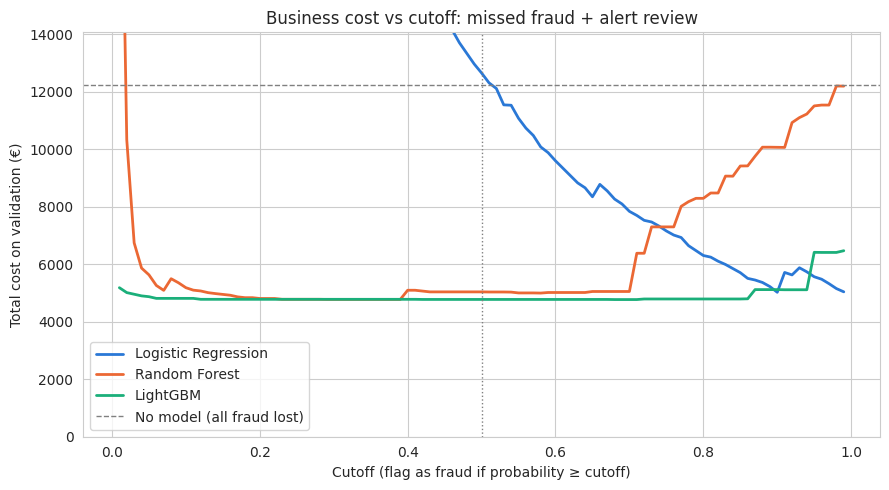

In [9]:
REVIEW_COST = 5.0   # € of analyst time to review one alert (assumption)

def business_cost(y_true, amount, prob, threshold, review_cost=REVIEW_COST):
    """Total € lost at a cutoff = missed fraud € + review €, at real-world volume."""
    y_true, amount = np.asarray(y_true), np.asarray(amount)
    flagged = prob >= threshold
    missed_eur   = amount[(y_true == 1) & ~flagged].sum()            # fraud we let through
    true_alerts  = ((y_true == 1) & flagged).sum()
    false_alerts = ((y_true == 0) & flagged).sum() * REAL_LEGIT_WEIGHT # scale to real volume
    review_eur   = (true_alerts + false_alerts) * review_cost          # every alert gets reviewed
    return missed_eur + review_eur

thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)
y_val, amt_val = val["Class"], val["Amount"]
no_model_cost = amt_val[y_val == 1].sum()          # no model → every fraud goes through

rows, curves = [], {}
for name, prob in val_probs.items():
    curves[name] = np.array([business_cost(y_val, amt_val, prob, t) for t in thresholds])
    rows.append({"Model": name,
                 "Cost @ 0.50 (€)": business_cost(y_val, amt_val, prob, 0.5),
                 "Cheapest cutoff": thresholds[curves[name].argmin()],
                 "Cost @ cheapest (€)": curves[name].min()})

cost_table = pd.DataFrame(rows).set_index("Model").sort_values("Cost @ cheapest (€)")
cost_table["Saved vs no model"] = 1 - cost_table["Cost @ cheapest (€)"] / no_model_cost
print(f"Validation: {y_val.sum()} frauds worth €{no_model_cost:,.0f} → that's the cost with NO model\n")
display(cost_table.round(2))

# RF and LightGBM tie within €4 (0.1%). Tie-break → LightGBM: flat cost curve
# (any cutoff ~0.06–0.86 works), identical results on any machine, trains in ~1 sec.
final_model = "LightGBM"
print(f"Cheapest model: {final_model}")

colors = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834", "LightGBM": "#1baf7a"}
fig, ax = plt.subplots(figsize=(9, 5))
for name, costs in curves.items():
    ax.plot(thresholds, costs, color=colors[name], linewidth=2, label=name)
ax.axhline(no_model_cost, color="gray", linestyle="--", linewidth=1, label="No model (all fraud lost)")
ax.axvline(0.5, color="gray", linestyle=":", linewidth=1)
ax.set_ylim(0, no_model_cost * 1.15)
ax.set_xlabel("Cutoff (flag as fraud if probability ≥ cutoff)")
ax.set_ylabel("Total cost on validation (€)")
ax.set_title("Business cost vs cutoff: missed fraud + alert review")
ax.legend(); plt.tight_layout(); plt.show()

## 7. Reliable Cutoff Selection (Walk-Forward Validation)
The validation window has only 57 frauds, too few to choose a cutoff reliably (the "cheapest" 0.13 is a noisy dip). Instead, we use **walk-forward validation** on the first 80% of time:
train on chunk 1 → predict chunk 2; train on chunks 1–2 → predict chunk 3; and so on.
Every prediction is made by a model that only saw **earlier** data, which gives ~250 frauds to choose the cutoff from instead of 57.

We also test how the best cutoff changes if reviewing an alert costs more or less than €5.

In [10]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

past = pd.concat([train, val]).reset_index(drop=True)     # first 80% of time
oof_prob = np.full(len(past), np.nan)

# Walk forward: train on earlier chunks, predict the next chunk
for fold, (tr_idx, te_idx) in enumerate(TimeSeriesSplit(n_splits=4).split(past), 1):
    m = clone(models[final_model]).fit(past.loc[tr_idx, FEATURES], past.loc[tr_idx, "Class"])
    oof_prob[te_idx] = m.predict_proba(past.loc[te_idx, FEATURES])[:, 1]
    print(f"Fold {fold}: trained on {len(tr_idx):,} rows → predicted next {len(te_idx):,} "
          f"({past.loc[te_idx, 'Class'].sum()} frauds)")

has_pred = ~np.isnan(oof_prob)                  # the first chunk is never predicted
y_oof, amt_oof, p_oof = past["Class"][has_pred], past["Amount"][has_pred], oof_prob[has_pred]
oof_costs = np.array([business_cost(y_oof, amt_oof, p_oof, t) for t in thresholds])
final_threshold = thresholds[oof_costs.argmin()]
print(f"\nCutoff chosen from {y_oof.sum()} out-of-fold frauds: {final_threshold}")
print(f"Cost there: €{oof_costs.min():,.0f}  vs  €{business_cost(y_oof, amt_oof, p_oof, 0.5):,.0f} at 0.50")

# What if reviewing an alert costs more or less than €5?
sens = []
for rc in [1, 5, 10, 25, 50]:
    c = np.array([business_cost(y_oof, amt_oof, p_oof, t, review_cost=rc) for t in thresholds])
    t = thresholds[c.argmin()]
    flagged = p_oof >= t
    sens.append({"Review cost / alert (€)": rc, "Best cutoff": t,
                 "Recall": ((y_oof == 1) & flagged).sum() / y_oof.sum(),
                 "False alarms (real-world)": round(((y_oof == 0) & flagged).sum() * REAL_LEGIT_WEIGHT)})
display(pd.DataFrame(sens).round(2))

Fold 1: trained on 8,071 rows → predicted next 8,070 (69 frauds)
Fold 2: trained on 16,141 rows → predicted next 8,070 (47 frauds)
Fold 3: trained on 24,211 rows → predicted next 8,070 (89 frauds)
Fold 4: trained on 32,281 rows → predicted next 8,070 (52 frauds)

Cutoff chosen from 257 out-of-fold frauds: 0.08
Cost there: €11,536  vs  €12,861 at 0.50


,Review cost / alert (€),Best cutoff,Recall,False alarms (real-world)
0,1,0.08,0.80,74
1,5,0.08,0.80,74
2,10,0.08,0.80,74
3,25,0.69,0.71,34
4,50,0.88,0.67,28


## 8. Final Evaluation on the Test Set (last 20% of time)
The chosen model (LightGBM) is retrained on **all past data** (first 80% of time) and scored once on the test set. We compare four strategies:
- **No model**: every fraud gets through.
- **Default cutoff (0.50)**: what most tutorials do.
- **Cutoff from validation only**: picked from just 57 frauds (the naive approach).
- **Cutoff from walk-forward validation (ours)**: picked from ~257 out-of-fold frauds.

In [11]:
from sklearn.base import clone

# Retrain the chosen model on ALL past data (first 80% of time)
final = clone(models[final_model]).fit(past[FEATURES], past["Class"])
p_test = final.predict_proba(test[FEATURES])[:, 1]
y_test, amt_test = test["Class"].values, test["Amount"].values

naive_threshold = cost_table.loc[final_model, "Cheapest cutoff"]   # picked from 57 frauds
no_model = amt_test[y_test == 1].sum()

rows = [{"Strategy": "No model", "Cutoff": None, "Caught": 0, "Missed": int(y_test.sum()),
         "False alarms (real-world)": 0, "Total cost (€)": no_model}]
for label, t in [("Default cutoff", 0.5),
                 ("Cutoff from validation only", naive_threshold),
                 ("Cutoff from walk-forward (ours)", final_threshold)]:
    flagged = p_test >= t
    rows.append({"Strategy": label, "Cutoff": t,
                 "Caught": int(((y_test == 1) & flagged).sum()),
                 "Missed": int(((y_test == 1) & ~flagged).sum()),
                 "False alarms (real-world)": round(((y_test == 0) & flagged).sum() * REAL_LEGIT_WEIGHT),
                 "Total cost (€)": business_cost(y_test, amt_test, p_test, t)})

final_table = pd.DataFrame(rows).set_index("Strategy")
final_table["Saved vs no model"] = 1 - final_table["Total cost (€)"] / no_model
print(f"TEST SET (last {(test['Time'].max() - test['Time'].min())/3600:.1f} hours): "
      f"{y_test.sum()} frauds worth €{no_model:,.0f}\n")
display(final_table.round(2))
display(pd.DataFrame([evaluate(f"{final_model} @ {final_threshold}", y_test, p_test, final_threshold)])
        .set_index("Model").round(3))

TEST SET (last 7.6 hours): 74 frauds worth €7,728



,Cutoff,Caught,Missed,False alarms (real-world),Total cost (€),Saved vs no model
Strategy,,,,,,
No model,NaN,0,74,0,7727.67,0.00
Default cutoff,0.50,55,19,11,2970.89,0.62
Cutoff from validation only,0.68,55,19,11,2970.89,0.62
Cutoff from walk-forward (ours),0.08,59,15,23,2806.52,0.64


,PR-AUC,PR-AUC (real-world),Recall,Precision,Precision (real-world),Caught,Missed,False alarms
Model,,,,,,,,
LightGBM @ 0.08,0.871,0.812,0.797,0.937,0.722,59,15,4


## 9. Limited Analyst Time: Which Alerts to Review First?
Real fraud teams can only review so many alerts per shift. If analysts can review only N alerts, which N?
- **Rank by probability**: review the most-likely-fraud transactions first.
- **Rank by expected loss** = probability × amount: review the transactions with the most **€ at risk** first.

A 90% fraud score on a €2 purchase puts €1.80 at risk; a 30% score on a €1,500 purchase puts €450 at risk.

,Alerts reviewed,€ caught: rank by probability,€ caught: rank by expected loss,Share of fraud € caught (expected loss)
0,10,355.61,4312.28,0.56
1,25,1413.33,5259.24,0.68
2,50,3790.42,6300.27,0.82
3,75,5344.94,6317.70,0.82
4,100,6340.33,6320.98,0.82
5,150,6370.03,6322.12,0.82


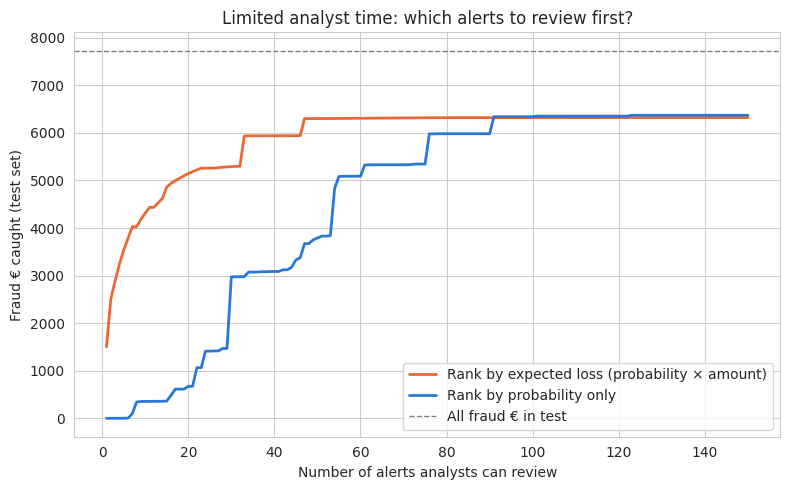

In [12]:
expected_loss = p_test * amt_test          # € we expect to lose if we DON'T review it
budgets = [10, 25, 50, 75, 100, 150]

def fraud_eur_caught(order, n):
    top = order[:n]                              # the n transactions analysts review
    return amt_test[top][y_test[top] == 1].sum()

by_prob = np.argsort(-p_test)                    # most likely fraud first
by_eur  = np.argsort(-expected_loss)             # most € at risk first

cap = pd.DataFrame({"Alerts reviewed": budgets,
                    "€ caught: rank by probability": [fraud_eur_caught(by_prob, n) for n in budgets],
                    "€ caught: rank by expected loss": [fraud_eur_caught(by_eur, n) for n in budgets]})
cap["Share of fraud € caught (expected loss)"] = cap["€ caught: rank by expected loss"] / no_model
display(cap.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
ns = np.arange(1, 151)
ax.plot(ns, [fraud_eur_caught(by_eur, n) for n in ns], color="#eb6834", linewidth=2,
        label="Rank by expected loss (probability × amount)")
ax.plot(ns, [fraud_eur_caught(by_prob, n) for n in ns], color="#2a78d6", linewidth=2,
        label="Rank by probability only")
ax.axhline(no_model, color="gray", linestyle="--", linewidth=1, label="All fraud € in test")
ax.set_xlabel("Number of alerts analysts can review")
ax.set_ylabel("Fraud € caught (test set)")
ax.set_title("Limited analyst time: which alerts to review first?")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 10. Explainability: Why Was This Transaction Flagged?
A fraud analyst can't act on "the model says 99%." They need to know **why**. SHAP splits each prediction into how much each feature pushed the fraud score up or down.
- **Global view:** which features matter most across all test transactions.
- **Local view:** a step-by-step breakdown for one flagged transaction, the explanation an analyst would see.

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


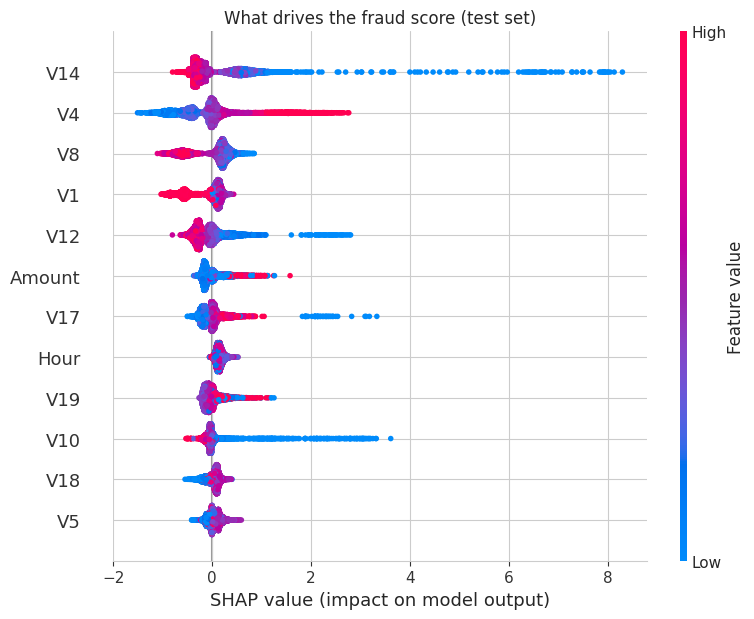

Transaction: €1,504.93 at hour 18, fraud probability 99.9%, actually fraud = True


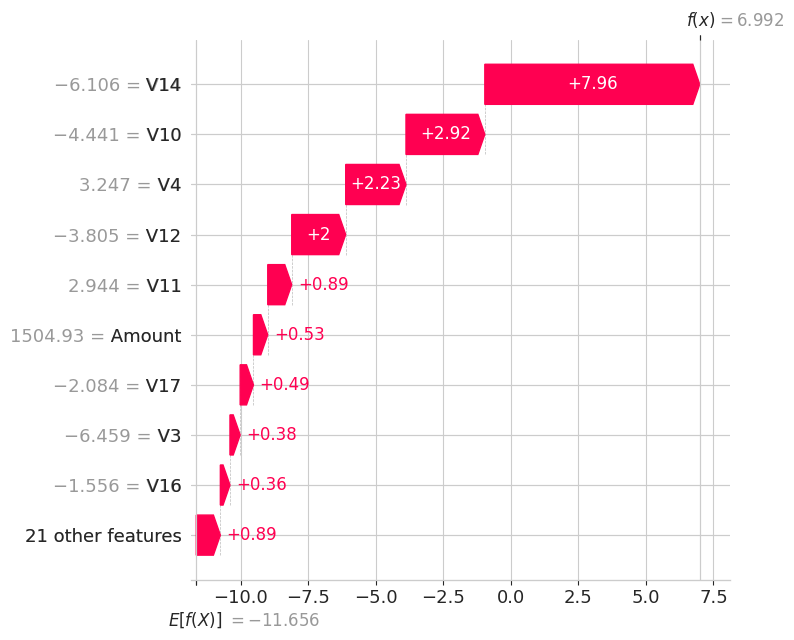

In [13]:
%pip install -q shap
import shap

explainer = shap.TreeExplainer(final)
shap_values = explainer.shap_values(test[FEATURES])     # one contribution per feature per row
if isinstance(shap_values, list):                       # older shap versions return [legit, fraud]
    shap_values = shap_values[1]

# (a) Global: which features drive fraud scores across the whole test set?
plt.figure()
shap.summary_plot(shap_values, test[FEATURES], max_display=12, show=False)
plt.title("What drives the fraud score (test set)"); plt.tight_layout(); plt.show()

# (b) Local: why was the riskiest caught fraud flagged?
caught = np.where((y_test == 1) & (p_test >= final_threshold))[0]
i = caught[np.argmax(expected_loss[caught])]                 # caught fraud with most € at risk
print(f"Transaction: €{amt_test[i]:,.2f} at hour {int(test['Hour'].iloc[i])}, "
      f"fraud probability {p_test[i]:.1%}, actually fraud = {bool(y_test[i])}")
plt.figure()
shap.plots.waterfall(shap.Explanation(values=shap_values[i],
                                      base_values=np.ravel(explainer.expected_value)[-1],
                                      data=test[FEATURES].iloc[i].values,
                                      feature_names=FEATURES), max_display=10, show=False)
plt.tight_layout(); plt.show()

## 11. Summary

| Strategy (test set, last 7.6 hours) | Caught (of 74) | Total cost | Saved vs no model |
|---|---|---|---|
| No model | 0 | €7,728 | 0% |
| Default cutoff (0.50) | 55 | €2,971 | 62% |
| **Walk-forward cost-optimized cutoff (0.08)** | **59** | **€2,807** | **64%** |

**Key findings**
1. **The random split flattered the base model.** Tested on future transactions, Random Forest recall fell from 81% to 73%.
2. **Fraud is ~3× more common at night** (2.68% vs 0.87%), so `Hour` replaced raw `Time`.
3. **Default thresholds can lose money.** Logistic Regression at 0.5 cost more than having no model at all (€12,652 vs €12,231 on validation).
4. **Choosing the cutoff from too little data is noisy.** Walk-forward validation (~257 frauds) gave a cutoff that beat the default on test: 4 more frauds caught, 64% of losses prevented.
5. **The right cutoff depends on business costs:** it stays stable for review costs of €1–€10 and should rise when reviews cost €25+.
6. **Queue order matters as much as the model.** Ranking alerts by expected loss (probability × amount) recovered 12× more € from the first 10 reviews, and 68% of all fraud € from 25 reviews.
7. **SHAP:** V14, V4, V8, V1 and V12 drive fraud scores, matching the EDA.

**Limitations:** two days of data; 74 test frauds (results can shift by a few transactions); €5 review cost is an assumption; anonymized PCA features limit domain interpretation.